# Data Preprocessing and Exploratory Data Analysis

This reduced version of Lab 2 focuses on a reusable workflow:

1. Load and inspect data.
2. Clean column names and missing values.
3. Prepare two datasets for merging.
4. Merge and summarize the data.
5. Perform a short EDA exercise.

The full solution notebook contains additional analyses under the supplementary material at the end. Those sections are optional.

We are going to use a COVID-19 Dataset (https://www.kaggle.com/datasets/imdevskp/corona-virus-report/data)

The description is the following:
- A new coronavirus designated 2019-nCoV was first identified in Wuhan, the capital of China's Hubei province
- People developed pneumonia without a clear cause and for which existing vaccines or treatments were not effective.
- The virus has shown evidence of human-to-human transmission
- Transmission rate (rate of infection) appeared to escalate in mid-January 2020
- As of 30 January 2020, approximately 8,243 cases have been confirmed

Dataset content:
- **covid_19_clean_complete.csv** - Day to day country wise no. of cases (Doesn't have County/State/Province level data)
- **worldometer_data.csv** - Latest data from https://www.worldometers.info/

The two datasets are similar in their goal but are structured very differently. They provide a good challenge to pre-process and analyse correctly.


### Understanding the unit of observation

A unit of observation is what one row represents. In the COVID dataset, a row represents a country or province on a particular date. In the Worldometer dataset, a row represents a country-level snapshot. Identifying the unit of observation helps us decide whether operations such as grouping and merging are meaningful.

## Recap from Lab 1

First, import the basic libraries for data analysis and manipulation: pandas (https://pandas.pydata.org/) and numpy (https://numpy.org/).

Pandas is used, among the other things, to read the csv files (and other formats) where datasets are stored. Sometimes, it might be necessary to change the options of the library, to allow to read large datasets. Otherwise, it might happen that only part of the dataset is loaded.

In this lab, we will use two files from the COVID-19 dataset: covid_19_clean_complete.csv and worldometer_data.csv.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.options.display.max_rows = 627920

## 1. Load and inspect the datasets

We inspect a dataset before changing it so that we understand its columns, data types, missing values, and unit of observation.

In [2]:
covid_complete = pd.read_csv('covid_19_clean_complete.csv')
worldometer = pd.read_csv('worldometer_data.csv')

print('Covid complete columns:', covid_complete.columns)
print('Worldometer columns:', worldometer.columns)

Covid complete columns: Index(['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed',
       'Deaths', 'Recovered', 'Active', 'WHO Region'],
      dtype='str')
Worldometer columns: Index(['Country/Region', 'Continent', 'Population', 'TotalCases', 'NewCases',
       'TotalDeaths', 'NewDeaths', 'TotalRecovered', 'NewRecovered',
       'ActiveCases', 'Serious,Critical', 'Tot Cases/1M pop', 'Deaths/1M pop',
       'TotalTests', 'Tests/1M pop', 'WHO Region'],
      dtype='str')


### **Examining the First Dataset: COVID-19 Clean Complete**

In this section we load the covid_19_clean_complete.csv file and we get some general information and statistics from it using the pandas library.

We first print a concise summary of a DataFrame using the `DataFrame.info()` function ([link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html)).

This method prints information about a DataFrame, including the index dtype, columns, non-null values, and memory usage. By examining the output, we can quickly classify each column as either **numerical** or **categorical**. Furthermore, within these two categories, we can further classify the columns into their respective subcategories:

- **Numerical Variables** can be:
  - **Discrete**: Countable values, like the number of confirmed cases or deaths.
  - **Continuous**: Variables that can take any value within a range, such as geographical coordinates like latitude and longitude.

- **Categorical Variables** can be:
  - **Nominal**: Categories without any inherent order, such as country names or WHO regions.
  - **Ordinal**: Categories with a meaningful order, like dates or rankings.

In this way, we gain not only an overview of the dataset’s structure but also a deeper understanding of the types of data it contains, which helps guide subsequent analysis steps.

In [3]:
covid_complete.info()

<class 'pandas.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  14664 non-null  str    
 1   Country/Region  49068 non-null  str    
 2   Lat             49068 non-null  float64
 3   Long            49068 non-null  float64
 4   Date            49068 non-null  str    
 5   Confirmed       49068 non-null  int64  
 6   Deaths          49068 non-null  int64  
 7   Recovered       49068 non-null  int64  
 8   Active          49068 non-null  int64  
 9   WHO Region      49068 non-null  str    
dtypes: float64(2), int64(4), str(4)
memory usage: 3.7 MB


### Variable Classification for the Covid Complete Dataset

- **Province/State**: Nominal
  - Represents the name of a specific province or state, which does not have any inherent order or numerical meaning.

- **Country/Region**: Nominal
  - Similar to the "Province/State" column, it contains the name of a country or region, and thus is a nominal variable without order or numerical meaning.

- **Lat (Latitude)**: Continuous
  - Latitude is a continuous variable, representing a geographical coordinate, where any value is possible within the range.

- **Long (Longitude)**: Continuous
  - Longitude is also a continuous variable, similar to latitude, representing geographical coordinates.

- **Date**: Ordinal
  - Although "Date" appears as an object, it represents a temporal sequence. Dates are treated as ordinal variables because they follow a natural order (i.e., one date is earlier or later than another).

- **Confirmed**: Discrete
  - The number of confirmed cases is a count, making it a discrete variable, as it can only take integer values.

- **Deaths**: Discrete
  - The number of deaths is also a count and a discrete variable for the same reasons as confirmed cases.

- **Recovered**: Discrete
  - Similarly, the number of recoveries is a count and thus considered a discrete variable.

- **Active**: Discrete
  - The number of active cases is also a count and, therefore, a discrete variable.

- **WHO Region**: Nominal
  - This column represents the region classification by WHO, making it a nominal variable, as it does not follow any inherent order.

### Summary:
- **Nominal Variables**: Province/State, Country/Region, WHO Region
- **Ordinal Variable**: Date
- **Continuous Variables**: Lat, Long
- **Discrete Variables**: Confirmed, Deaths, Recovered, Active


---

### Inspect quickly the first and last rows
The `head()`/`tail()` functions in pandas allow you to preview the first/last 5 rows of a DataFrame. By default, it shows the first 5 rows, but you can specify a different number of rows if needed.

**Syntax**: `df.head(n)`  
- `n` (optional): The number of rows to display. If not specified, the default is 5.

This method is useful for quickly inspecting the top/last rows of a dataset to understand its structure and contents.

In [4]:
covid_complete.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


In [5]:
covid_complete.tail()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
49063,NaN,Sao Tome and Principe,0.186400,6.613100,2020-07-27,865,14,734,117,Africa
49064,NaN,Yemen,15.552727,48.516388,2020-07-27,1691,483,833,375,Eastern Mediterranean
49065,NaN,Comoros,-11.645500,43.333300,2020-07-27,354,7,328,19,Africa
49066,NaN,Tajikistan,38.861000,71.276100,2020-07-27,7235,60,6028,1147,Europe
49067,NaN,Lesotho,-29.610000,28.233600,2020-07-27,505,12,128,365,Africa


### Interpreting the `head()` and `tail()` Commands

Both commands provide a quick glimpse of the data, allowing us to check the structure and content of the dataset.

- **`head()`**:
  - We can observe that the **Province/State** column contains missing values (NaN) for all initial rows, indicating that some countries may not have state-level data available.
  - The **Confirmed**, **Deaths**, **Recovered**, and **Active** cases are all zero for these first five records, which correspond to the starting date of the pandemic (2020-01-22).
  - The **WHO Region** is clearly populated, showing the regional classification for each country/region.

- **`tail()`**:
  The `covid_complete.tail()`is allowing us to examine the most recent data points in the dataset. In this case, the data corresponds to July 27, 2020.
  - We can observe that **Province/State** remains missing for these records, suggesting that this column contains a significant amount of missing data.
  - The **Confirmed**, **Deaths**, **Recovered**, and **Active** cases are populated, indicating that the pandemic had progressed significantly by this time.
  - The **WHO Region** is also consistently populated, and we can observe the distribution of cases across different countries in regions such as Africa, Europe, and the Eastern Mediterranean.

By using both `head()` and `tail()`, we gain a quick overview of the initial and most recent records in the dataset, allowing us to understand how the pandemic data is structured and how it has evolved over time.


---

### Get desriptive statistics

We can now get more information, such as mean, median, mode, standard deviation, and percentiles of fields to summarize the central tendency and spread of the data. We use the DataFrame.describe (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html) function.

Since these values are floats with a lot of digits, we change the settings of pandas to limit the number of digits after the dot to 2. We use pandas.set_option() function (https://pandas.pydata.org/docs/user_guide/options.html).

In [6]:
pd.set_option('display.float_format', '{:.2f}'.format)

covid_complete.describe()

,Lat,Long,Confirmed,Deaths,Recovered,Active
count,49068.00,49068.00,49068.00,49068.00,49068.00,49068.00
mean,21.43,23.53,16884.90,884.18,7915.71,8085.01
std,24.95,70.44,127300.21,6313.58,54800.92,76258.90
min,-51.80,-135.00,0.00,0.00,0.00,-14.00
25%,7.87,-15.31,4.00,0.00,0.00,0.00
50%,23.63,21.75,168.00,2.00,29.00,26.00
75%,41.20,80.77,1518.25,30.00,666.00,606.00
max,71.71,178.06,4290259.00,148011.00,1846641.00,2816444.00


### Interpretation of Summary Statistics for the Covid Complete Dataset:

- **Latitude (Lat) and Longitude (Long)**:
  - The dataset spans a wide geographic area, with latitude ranging from -51.8 to 71.71 degrees, and longitude from -135.0 to 178.06 degrees, indicating global coverage.
  - The mean latitude is 21.43, and the mean longitude is 23.53, suggesting that most data points lie in regions closer to the equator.

- **Confirmed Cases**:
  - The number of confirmed cases varies greatly across regions, with a minimum of 0 and a maximum of 4,290,259 cases.
  - The median (50th percentile) number of confirmed cases is 168, which indicates that half of the regions have fewer than 168 confirmed cases, while the other half have more.
  - The mean number of confirmed cases is 16,884.90, but the large standard deviation (127,300.21) indicates significant variation in the number of confirmed cases across different regions.

- **Deaths**:
  - The death count ranges from 0 to a maximum of 1,480,011 deaths in a region, with a median of only 2, indicating that many regions have relatively low death counts.
  - The mean death count is 884.18, and again, the large standard deviation (6,313.58) suggests a wide disparity in death counts across regions.

- **Recovered**:
  - The recovery numbers show a broad range, with a minimum of 0 and a maximum of 1,846,641 recoveries in a region.
  - The median number of recoveries is 29, and the mean is 7,915.71, but the large standard deviation (54,800.92) indicates significant variation across regions.

- **Active Cases**:
  - Active cases range from -14 to 2,816,444. The negative minimum could indicate some data issues or misreporting for a small number of regions.
  - The median active cases is 26, with a mean of 8,085.01, and the standard deviation is quite high (76,258.90), suggesting considerable variability in the number of active cases between regions.

### General Insights:
- The data shows a large disparity in the number of confirmed, death, recovered, and active cases across different regions.
- Many regions appear to have relatively low confirmed cases and deaths (as indicated by the low medians) but a few regions exhibit extremely high values which pulls the mean up significantly and results in large standard deviations.


### **Loading the Second Dataset: Worldometer Data**

We perform the same operations as we did with the first dataset also for worldometer_data.csv. In this case, we have 16 columns.

In [7]:
worldometer.info()

<class 'pandas.DataFrame'>
RangeIndex: 209 entries, 0 to 208
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Country/Region    209 non-null    str    
 1   Continent         208 non-null    str    
 2   Population        208 non-null    float64
 3   TotalCases        209 non-null    int64  
 4   NewCases          4 non-null      float64
 5   TotalDeaths       188 non-null    float64
 6   NewDeaths         3 non-null      float64
 7   TotalRecovered    205 non-null    float64
 8   NewRecovered      3 non-null      float64
 9   ActiveCases       205 non-null    float64
 10  Serious,Critical  122 non-null    float64
 11  Tot Cases/1M pop  208 non-null    float64
 12  Deaths/1M pop     187 non-null    float64
 13  TotalTests        191 non-null    float64
 14  Tests/1M pop      191 non-null    float64
 15  WHO Region        184 non-null    str    
dtypes: float64(12), int64(1), str(3)
memory usage: 26.3 KB


### Variable Classification for the Worldometer Dataset

- **Nominal Variables**: Country/Region, Continent, WHO Region
- **Continuous Variables**: Population, Tot Cases/1M pop, Deaths/1M pop, Tests/1M pop
- **Discrete Variables**: TotalCases, NewCases, TotalDeaths, NewDeaths, TotalRecovered, NewRecovered, ActiveCases, Serious,Critical, TotalTests

---

### **Inspect rows and find descriptive statistics for columns**

In [8]:
worldometer.head()

,Country/Region,Continent,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region
0,USA,North America,331198130.00,5032179,NaN,162804.00,NaN,2576668.00,NaN,2292707.00,18296.00,15194.00,492.00,63139605.00,190640.00,Americas
1,Brazil,South America,212710692.00,2917562,NaN,98644.00,NaN,2047660.00,NaN,771258.00,8318.00,13716.00,464.00,13206188.00,62085.00,Americas
2,India,Asia,1381344997.00,2025409,NaN,41638.00,NaN,1377384.00,NaN,606387.00,8944.00,1466.00,30.00,22149351.00,16035.00,South-EastAsia
3,Russia,Europe,145940924.00,871894,NaN,14606.00,NaN,676357.00,NaN,180931.00,2300.00,5974.00,100.00,29716907.00,203623.00,Europe
4,South Africa,Africa,59381566.00,538184,NaN,9604.00,NaN,387316.00,NaN,141264.00,539.00,9063.00,162.00,3149807.00,53044.00,Africa


In [9]:
worldometer.tail()

,Country/Region,Continent,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region
204,Montserrat,North America,4992.00,13,NaN,1.00,NaN,10.00,NaN,2.00,NaN,2604.00,200.00,61.00,12220.00,NaN
205,Caribbean Netherlands,North America,26247.00,13,NaN,NaN,NaN,7.00,NaN,6.00,NaN,495.00,NaN,424.00,16154.00,NaN
206,Falkland Islands,South America,3489.00,13,NaN,NaN,NaN,13.00,NaN,0.00,NaN,3726.00,NaN,1816.00,520493.00,NaN
207,Vatican City,Europe,801.00,12,NaN,NaN,NaN,12.00,NaN,0.00,NaN,14981.00,NaN,NaN,NaN,Europe
208,Western Sahara,Africa,598682.00,10,NaN,1.00,NaN,8.00,NaN,1.00,NaN,17.00,2.00,NaN,NaN,Africa


In [10]:
pd.set_option('display.float_format', '{:.2f}'.format)

worldometer.describe()

,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop
count,208.00,209.00,4.00,188.00,3.00,205.00,3.00,205.00,122.00,208.00,187.00,191.00,191.00
mean,30415486.97,91718.50,1980.50,3792.59,300.00,58878.98,1706.00,27664.33,534.39,3196.02,98.68,1402404.70,83959.37
std,104766099.48,432586.68,3129.61,15487.18,451.20,256698.41,2154.78,174632.74,2047.52,5191.99,174.96,5553366.67,152730.59
min,801.00,10.00,20.00,1.00,1.00,7.00,42.00,0.00,1.00,3.00,0.08,61.00,4.00
25%,966314.00,712.00,27.50,22.00,40.50,334.00,489.00,86.00,3.25,282.00,6.00,25752.00,8956.50
50%,7041972.50,4491.00,656.00,113.00,80.00,2178.00,936.00,899.00,27.50,1015.00,29.00,135702.00,32585.00
75%,25756135.50,36896.00,2609.00,786.00,449.50,20553.00,2538.00,7124.00,160.25,3841.75,98.00,757696.00,92154.50
max,1381344997.00,5032179.00,6590.00,162804.00,819.00,2576668.00,4140.00,2292707.00,18296.00,39922.00,1238.00,63139605.00,995282.00


### Interpretation of Summary Statistics for the Worldometer Dataset

- **Population**:
  - The population values range from a minimum of 801 to a maximum of 1.38 billion, with a mean population of approximately 304 million.
  - This large standard deviation (1.04 billion) indicates a wide variation in population sizes across countries/regions.

- **TotalCases**:
  - The total number of cases ranges from 20 to over 5 million, with a median (50th percentile) of 4,491 cases.
  - The mean of approximately 91,718 cases is heavily skewed by countries with large case numbers, as seen by the high standard deviation (432,586.88).

- **NewCases**:
  - New cases range from 10 to 6,590, with only 4 entries in this column, which may indicate limited reporting of recent data on new cases.

- **TotalDeaths**:
  - The number of deaths varies widely from 1 to 162,804, with a mean of 3,792 and a median of 656.
  - The large standard deviation (15,487.18) shows that a few countries have significantly higher death tolls compared to the majority.

- **NewDeaths**:
  - The new deaths range from 0 to 819, but with only 3 non-null values, suggesting the data for new deaths is not widely available in this dataset.

- **TotalRecovered**:
  - Total recoveries range from 7 to 2.57 million, with a mean of 588,789 and a median of 217,780.
  - The large standard deviation (256,698.41) indicates significant disparity between countries' recovery numbers.

- **NewRecovered**:
  - There are 3 entries for new recoveries, ranging from 42 to 4,140.

- **ActiveCases**:
  - The number of active cases ranges from 42 to 2.29 million, with a median of 936.
  - The mean is 27,664, and the standard deviation is high (174,632.74), reflecting the wide spread between countries.

- **Serious,Critical**:
  - The number of serious or critical cases ranges from 1 to 18,296, with 122 non-null values.
  - The median is 899, but the high standard deviation (2,047.52) suggests a few countries have a disproportionately high number of critical cases.

- **Tot Cases/1M pop**:
  - The total cases per million people range from 3 to 39,922, with a median of 27,750 and a mean of 3,196.
  - The large standard deviation (5,191.99) indicates that some countries have significantly higher cases per capita than others.

- **Deaths/1M pop**:
  - Deaths per million range from 0.08 to 1,238, with a median of 29 and a mean of 98.68.
  - The high standard deviation (174.96) indicates that a small number of countries have much higher death rates per million compared to others.

- **TotalTests**:
  - The total number of tests conducted varies greatly, from as few as 61 to over 63 million, with a median of 135,702 tests.
  - The mean is 1.4 million, and the standard deviation is very high (5.55 million), suggesting a wide disparity in testing capabilities across countries.

- **Tests/1M pop**:
  - Tests per million population range from 4 to nearly 1 million, with a mean of 83,959 and a median of 32,585.
  - The large standard deviation (152,730.59) indicates significant variation in the number of tests conducted per capita across different countries.

### General Insights:
- The dataset shows large differences across countries in key COVID-19 metrics like population, confirmed cases, deaths, recoveries, and testing.
- Some countries have extremely high values (e.g., millions of cases or tests), which pull the average up. This results in high variability, reflected in the large standard deviations.
- The **median** values are often more representative of the typical country’s situation since they are less affected by countries with extreme numbers.


---

## 2. Preprocessing and data cleaning'

The goal preprocessing is to clean, format, and organize the data in such a way that ML models can be trained efficiently, and meaningful insights can be extracted. Raw data typically contains noise, missing values, and inconsistencies, so preprocessing is essential to ensure data quality and improve model performance.

### **Renaming Columns**

One first step, not mandatory but recommended, is to rename columns. By looking at the results of the previous step, we can see how the names of the columns sometimes have spaces, slashes, camel case and other details that make names inconsistent.

It is a good practice to standardize columns names, so that, when a machine need to read the values, it is easier to program.

To do that, we use the DataFrame.remane() function with the option columns (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rename.html).

In [11]:
covid_complete = covid_complete.rename(columns={
    'Province/State': 'state',
    'Country/Region': 'country',
    'Lat': 'lat',
    'Long': 'long',
    'Date': 'date',
    'Confirmed': 'confirmed',
    'Deaths': 'deaths',
    'Recovered': 'recovered',
    'Active': 'active',
    'WHO Region': 'who_region'
})

worldometer = worldometer.rename(columns={
    'Country/Region': 'country',
    'Continent': 'continent',
    'Population': 'population',
    'TotalCases': 'total_cases',
    'NewCases': 'new_cases',
    'TotalDeaths': 'total_deaths',
    'NewDeaths': 'new_deaths',
    'TotalRecovered': 'total_recovered',
    'NewRecovered': 'new_recovered',
    'ActiveCases': 'active_cases',
    'Serious,Critical': 'serious_critical',
    'Tot Cases/1M pop': 'total_cases_per_1m',
    'Deaths/1M pop': 'deaths_per_1m',
    'TotalTests': 'total_tests',
    'Tests/1M pop': 'tests_per_1m',
    'WHO Region': 'who_region'
})

### Cleaning the COVID dataset

One of the primary tasks in data cleaning involves handling missing data. This can happen when certain entries are left blank due to human error, system issues, or incomplete data collection. Missing data can be addressed in a few ways: one can remove the rows or columns with missing values if their absence doesn't significantly affect the dataset, or use imputation techniques to fill in the blanks with substituted values like the mean, median, or most frequent entry.

In our case, removing the null fields is sufficient.

So, here we want to understand:


*   **Are there null values?**
*   **If yes, how do we fix them?**
*   **It is better to drop columns, rows or replace the null values with a default value?**



### **Cleaning covid_complete: remove null fields**

First, as reminder, we print the shape of the dataset: 49068 rows and 10 columns. We use the Dataframe.shape property (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html).

In [12]:
covid_complete.shape

(49068, 10)

Then, we the sum of null values for each field. We use DataFrame.isnull() to get the null values (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html).

As we can observe, the only null values (34404) appear in the state column. In our case, we will not perform any operation that involves this field, so we can simply drop the column. However, in other situation, it might be better to resort to other techniques.

In [13]:
covid_complete.isnull().sum()

state         34404
country           0
lat               0
long              0
date              0
confirmed         0
deaths            0
recovered         0
active            0
who_region        0
dtype: int64

---

### The `drop()` Function in pandas

The `drop()` function in pandas is used to remove rows or columns from a DataFrame. You can specify:
- **`axis=0`** to drop rows (default behavior).
- **`axis=1`** to drop columns.

You can drop elements by providing their labels (index for rows or column names for columns). By default, `drop()` returns a new DataFrame and leaves the original unchanged, so assign the result to a variable when you want to keep the change. Although older examples may use `inplace=True`, this option is deprecated in newer pandas versions and is best avoided. 

This function is commonly used to clean data by removing unwanted rows or columns.


DataFrame.drop() function full documentation (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.drop.html).

Our goal is to delete the `state` column. 

Then we print again the null values to verify the operation happened successfully: the column state is not there anymore.

In [14]:
covid_complete = covid_complete.drop(['state'], axis=1)

covid_complete.isnull().sum()

country       0
lat           0
long          0
date          0
confirmed     0
deaths        0
recovered     0
active        0
who_region    0
dtype: int64

And the shape of the dataset changed, with the same amount of rows but one less column.

In [15]:
covid_complete.shape

(49068, 9)

### **Cleaning worldometer: remove null fields**

We perform similar operation for the second dataframe, as we did for the first one.

In this section, however, we highlight the difference between dropping a column, or removing the actual null values with the DataFrame.dropna() function (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html).

### Dropping rows versus imputing values

dropna removes missing values. Dropping rows from the Worldometer snapshot may discard most of the countries.

In [16]:
worldometer_remove_null_rows = worldometer.dropna()
print('Original shape:', worldometer.shape)
print('Shape after dropping incomplete rows:', worldometer_remove_null_rows.shape)

Original shape: (209, 16)
Shape after dropping incomplete rows: (3, 16)


### Dropping rows versus removing columns

DataFrame.dropna removes observations or variables containing missing values. Calling dropna without an axis removes rows, while dropna(axis=1) removes columns. Dropping can be appropriate when incomplete observations cannot be used, but it can also remove a large amount of data. That is why we inspect the resulting shape.

### Imputing a missing value

For the North American subset, we replace the missing value in new_recovered with zero.

This is a **domain assumption** for this demonstration. We assume that a missing value means that no new recoveries were reported:

A missing new_recovered value is treated as zero newly reported recoveries.

However, a missing value does not necessarily mean zero. It could mean that the information was not collected, was not reported, or was unavailable. Replacing it with zero therefore changes the data and may affect later calculations.

An alternative is to leave the value as NaN. This preserves the distinction between “zero” and “unknown” and avoids discarding the entire country row. Many pandas calculations ignore NaN values by default, although this depends on the operation. Other analyses, such as some visualizations or machine-learning models, may require missing values to be handled explicitly.

In practice, deciding between leaving a value missing, replacing it, or removing the observation requires domain knowledge about what missingness means in that particular column. We do not have enough domain information within this lab to make that decision confidently.

Therefore, we keep the zero-imputation assumption in this example and in this lab for simplicity sake. The goal is to demonstrate how `DataFrame.fillna()` works.

We can use the `DataFrame.fillna()` function ([link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.fillna.html)) to replace null values with specific values. This function allows you to assign values to nulls in specific columns or across the entire DataFrame.

For instance, in the Worldometer dataset, we will fill the `new_recovered` column with `0` as explained above.

### Additional Information:
- You can use `fillna()` to replace null values with a constant, a dictionary (for column-wise replacements), or even with values from another column.
- The `inplace=True` option allows you to modify the DataFrame directly without creating a new copy.
- It also supports methods like `ffill` (forward fill) and `bfill` (backward fill) to propagate non-null values in case you're working with time-series data.

This method is particularly useful when you want to maintain the size of the dataset by filling in meaningful values for missing data, rather than removing rows or columns.

In [17]:
worldometer_north_america = worldometer[
    worldometer['continent'] == 'North America'
].copy()

print('Missing values before imputation:')
print(worldometer_north_america['new_recovered'].isnull().sum())

worldometer_north_america['new_recovered'] = (
    worldometer_north_america['new_recovered'].fillna(0)
)

print('Missing values after imputation:')
print(worldometer_north_america['new_recovered'].isnull().sum())

Missing values before imputation:
34
Missing values after imputation:
0


## 3. Prepare and join the datasets

We have explored how the COVID-19 data is composed of several datasets, each containing different types of information. Often, this information refers to the same data points across different CSV files. In principle, to gain deeper insights, it is crucial to utilize all available information by combining these datasets.

#### **On what basis can we merge two datasets? In this scenario, which column would be the best to use as the key? Is it even possible/logical?**

Spoilers: Answer is below

In [18]:
print(covid_complete.shape)
worldometer.shape

(49068, 9)


(209, 16)

### The `unique()` Function

The `unique()` method returns an array of all unique values in a Series. It is useful for identifying distinct entries in a column, such as countries in our datasets.

Both the `covid_complete` and `worldometer` datasets contain the `Country/Region` column as a common key, which can be used to merge the two datasets. Before proceeding, let's first check if they have the same number of countries.

We can do this using the `unique()` method in combination with `len()`. By applying `len()` to the result of `unique()`, we can count the number of unique countries in each dataset.

Let’s print the number of unique countries in both `covid_complete` and `worldometer`.


In [19]:
# There are at least two different ways to print this statement
print(f'The covid_commplete contains:  { len(covid_complete['country'].unique()) } unique countries.')
print('The worldometer contains: ' + str(len(worldometer['country'].unique())) + ' unique countries.')

The covid_commplete contains:  187 unique countries.
The worldometer contains: 209 unique countries.


In [20]:
print(f"Difference in number of countries: {abs(len(covid_complete['country'].unique()) - len(worldometer['country'].unique()))}")

Difference in number of countries: 22


The [`set()`](https://docs.python.org/3/tutorial/datastructures.html#sets) function removes duplicates and it is the pythonic way of handling unique values as well as do comparison with other sets. 

Converting the dataframe column to sets allows us to use set differences. The two differences answer two separate questions: which names appear only in the COVID data, and which names appear only in the Worldometer data. These checks help us discover unmatched keys before merging.

In [21]:
covid_countries = set(covid_complete['country'])
worldometer_countries = set(worldometer['country'])

In [22]:
missing_in_worldometer = covid_countries - worldometer_countries
print("Countries in covid_complete but missing from worldometer:")
print(missing_in_worldometer)

Countries in covid_complete but missing from worldometer:
{'Taiwan*', 'Congo (Brazzaville)', 'Brunei', 'Congo (Kinshasa)', 'China', 'United Kingdom', 'Kosovo', 'Saint Vincent and the Grenadines', 'West Bank and Gaza', 'Holy See', 'US', 'Burma', 'United Arab Emirates', 'Central African Republic', "Cote d'Ivoire", 'South Korea'}


### Importance of Preprocessing Before Merging

Preprocessing is a crucial step before merging datasets to handle inconsistencies in common columns like `Country/Region`. Initially, important countries like "US" and "United Kingdom" had discrepancies between the `covid_complete` and `worldometer` datasets, causing them not to match.

Without the preprocessing step (which normalized and corrected country names), these countries won't align during the merge, leading to lost records. By addressing these inconsistencies beforehand, we ensure that key countries are properly matched, preserving more data during the merging process. We will try to do that below.




### Handling inconsistent country names

The following code addresses inconsistencies in country names between the `covid_complete` and `worldometer` datasets. It normalizes country names by converting them to lowercase and removing extra spaces, and applies manual corrections for name mismatches. This ensures that both datasets are aligned, making it possible to compare and merge them effectively.

In [23]:
# Normalize the country names by stripping whitespace and converting to lowercase
covid_complete['country'] = covid_complete['country'].str.strip().str.lower()
worldometer['country'] = worldometer['country'].str.strip().str.lower()

# Define a manual mapping to fix discrepancies between the two datasets
name_corrections = {
    'usa': 'us',
    'uae': 'united arab emirates',
    's. korea': 'south korea',
    'burma': 'myanmar',
    'holy see': 'vatican city',
    'west bank and gaza': 'palestine',
    'cote d\'ivoire': 'ivory coast',
    'taiwan': 'taiwan*',
    'congo': 'congo (brazzaville)',
    'drc': 'congo (kinshasa)',
    'central african republic': 'car',
    'st. vincent grenadines': 'saint vincent and the grenadines',
    'uk': 'united kingdom'
}

# Apply the name corrections to both datasets
covid_complete['country'] = covid_complete['country'].replace(name_corrections)
worldometer['country'] = worldometer['country'].replace(name_corrections)

# Re-run the comparison to see if there are still discrepancies
covid_countries = set(covid_complete['country'])
worldometer_countries = set(worldometer['country'])

# Find discrepancies
missing_in_worldometer = covid_countries - worldometer_countries
missing_in_covid = worldometer_countries - covid_countries

# Print missing countries
print("Countries in covid_complete but missing from worldometer:", missing_in_worldometer)
print("Countries in worldometer but missing from covid_complete:", missing_in_covid)

# Print the difference in the number of countries after applying corrections
print(f"\nNumber of countries in covid_complete: {len(covid_countries)}")
print(f"Number of countries in worldometer: {len(worldometer_countries)}")
print(f"Difference in number of countries: {abs(len(covid_countries) - len(worldometer_countries))}")

Countries in covid_complete but missing from worldometer: {'china', 'kosovo'}
Countries in worldometer but missing from covid_complete: {'curaçao', 'french guiana', 'cayman islands', 'french polynesia', 'channel islands', 'faeroe islands', 'mayotte', 'falkland islands', 'gibraltar', 'guadeloupe', 'new caledonia', 'bermuda', 'martinique', 'aruba', 'turks and caicos', 'isle of man', 'réunion', 'saint martin', 'sint maarten', 'diamond princess', 'macao', 'montserrat', 'caribbean netherlands', 'hong kong'}

Number of countries in covid_complete: 187
Number of countries in worldometer: 209
Difference in number of countries: 22


### Code Interpretation

This code addresses inconsistencies in country names between the `covid_complete` and `worldometer` datasets by normalizing the values, applying manual corrections, and identifying any remaining discrepancies.

- **Normalization**: The country names in both datasets are normalized by removing any leading or trailing whitespace and converting them to lowercase. This ensures uniformity in formatting, which is essential for accurate comparison.

- **Manual Corrections**: A dictionary called `name_corrections` is created to fix discrepancies in country names (e.g., "usa" is corrected to "us", "s. korea" to "south korea"). This step ensures that common country names are consistent across both datasets.

- **Applying Corrections**: The `.replace()` method is used to apply the manual corrections to the country columns in both datasets.

- **Comparison**: The unique country names from both datasets are extracted using `.unique()` and converted into sets. This enables easy comparison to identify which countries are missing from either dataset.

- **Identifying Missing Countries**: The set difference operation (`-`) is used to find countries that are present in one dataset but missing from the other.

# If you reach this point, answer now before reading the spoilers below. Should we actually merge the two datasets and why?

### Merging the datasets: an important warning

The pandas merge function combines columns from two tables when the values in one or more key columns match. Here, country is used as the key, so pandas searches for the same country name in both tables.

Before merging, ask two questions:

1. What does one row represent in each dataset?
2. Do the key columns describe the same unit of observation and the same point in time?

The cleaned COVID dataset is a time series. A row represents a country (and, in some cases, a state or province) on a particular date. The Worldometer dataset is a country-level snapshot: it contains one row per country, but it has no date that can be aligned with the COVID observations.

The code uses an inner merge, which keeps only countries found in both tables. The validate='many_to_one' argument checks our structural expectation: the COVID table may contain many rows for one country because it contains many dates, while the Worldometer table should contain at most one row for that country. The suffixes distinguish columns with the same name in the two input tables.

This merge is useful as a teaching example, but it is a bad analytical merge for comparing COVID trends. The Worldometer snapshot values are copied onto every matching COVID date. If we later sum a Worldometer column after this merge, we count the same snapshot repeatedly and obtain an inflated, meaningless result. A successful merge only tells us that the keys matched; it does not prove that the resulting analysis is scientifically valid.

For the main lab, inspect the result and identify the repeated snapshot values. In a real analysis, we would use the COVID time series by itself, aggregate both datasets to one row per country before comparing them, or merge on country and a compatible date when both datasets genuinely contain matching dates.

In [24]:
# using pandas merge (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html)
merged_df = pd.merge(
    covid_complete,
    worldometer,
    on='country',
    how='inner',
    validate="many_to_one",
    suffixes=('_covid', '_worldometer')
)

print('Merged shape:', merged_df.shape)
merged_df.head()

Merged shape: (42676, 24)


,country,lat,long,date,confirmed,deaths,recovered,active,who_region_covid,continent,...,new_deaths,total_recovered,new_recovered,active_cases,serious_critical,total_cases_per_1m,deaths_per_1m,total_tests,tests_per_1m,who_region_worldometer
0,afghanistan,33.94,67.71,2020-01-22,0,0,0,0,Eastern Mediterranean,Asia,...,NaN,25840.00,NaN,9758.00,31.00,946.00,33.00,90396.00,2317.00,EasternMediterranean
1,albania,41.15,20.17,2020-01-22,0,0,0,0,Europe,Europe,...,NaN,3155.00,NaN,2673.00,23.00,2091.00,65.00,38997.00,13553.00,Europe
2,algeria,28.03,1.66,2020-01-22,0,0,0,0,Africa,Africa,...,NaN,23238.00,NaN,9115.00,57.00,766.00,29.00,NaN,NaN,Africa
3,andorra,42.51,1.52,2020-01-22,0,0,0,0,Europe,Europe,...,NaN,828.00,NaN,64.00,1.00,12216.00,673.00,3750.00,48526.00,Europe
4,angola,-11.20,17.87,2020-01-22,0,0,0,0,Africa,Africa,...,NaN,520.00,NaN,899.00,20.00,45.00,2.00,64747.00,1965.00,Africa


#### Understanding the merge arguments

on='country' tells pandas which column contains the matching key. how='inner' keeps only keys present in both tables. validate='many_to_one' checks the expected structure: many COVID rows may match one Worldometer row for the same country. The suffixes argument makes overlapping column names distinguishable.

#### Important temporal warning

The merge key identifies the country but not the date. Consequently, one Worldometer snapshot row is attached to many daily COVID rows. The merge is structurally valid, but it is not temporally aligned. This distinction is central: a technically successful merge can still be inappropriate for a scientific interpretation.

#### Reading the merged result

The merged DataFrame has many rows per country because the COVID dataset is a time series. Before interpreting a result, ask: what does one row represent, which values are cumulative, and which values came from a snapshot?

### GroupBy aggregation: split–apply–combine

The groupby method organizes rows into groups, after which an aggregation such as sum, mean, count, min, or max can be applied to each group. The results are then combined into a new, smaller table.

This is called split–apply–combine:

1. Split the data into groups with the same value in one or more columns.
2. Apply a calculation to each group.
3. Combine the group-level results.

For a formal reference, see the official pandas guide to the [split–apply–combine pattern](https://pandas.pydata.org/docs/user_guide/groupby.html). This guide explains how `groupby()` splits a dataset into groups, applies calculations to those groups, and combines the results into a new DataFrame.

The COVID table has many observations for one country because it records multiple dates. Grouping by country therefore lets us calculate one result per country. However, the calculation must match the meaning of the data.

In the following example, the sums demonstrate the pandas mechanics, but they should not be reported as real totals. The COVID columns are cumulative values, so summing them over dates counts earlier cases repeatedly. The Worldometer columns are snapshot values, and the country-only merge repeats them across the COVID dates, so summing them is also invalid.

Treat this result as a diagnostic exercise: inspect the values and explain why they are inflated. A safer country-level summary appears later in the optional Supplementary Material. It first aggregates the time series by country and date and then takes the latest observed cumulative value.

For a formal reference, see the official pandas guide on GroupBy and split–apply–combine:
https://pandas.pydata.org/docs/user_guide/groupby.html

In [25]:
grouped_df_merge = (
    merged_df.groupby('country')[['confirmed', 'deaths', 'recovered']]
    .sum()
)

grouped_df_merge.head()

,confirmed,deaths,recovered
country,,,
afghanistan,1936390,49098,798240
albania,196702,5708,118877
algeria,1179755,77972,755897
andorra,94404,5423,69074
angola,22662,1078,6573


### Reading the grouped result

After grouping by country, the index contains one country label per row. The selected numerical columns have been summarized. This is useful for learning the syntax, but summing cumulative daily counts produces inflated totals because the same cases appear repeatedly over time.

#### Revisit the analysis while accounting for the temporal structure of the data
Repeat the analysis using an approach that respects the dates and changing values over time.

In [26]:
grouped_df_merge = (
    merged_df.groupby('country')[['confirmed', 'deaths', 'recovered']]
    .max()
)

grouped_df_merge.head()

,confirmed,deaths,recovered
country,,,
afghanistan,36263,1269,25198
albania,4880,144,2745
algeria,27973,1163,18837
andorra,907,52,803
angola,950,41,242


In [27]:
# This is an alternative solution.
# For cumulative, non-decreasing time-series variables, the maximum
# represents the latest value. For other variables, select the latest date instead.

covid_time_series = covid_complete.copy()

covid_time_series["date"] = pd.to_datetime(
    covid_time_series["date"]
)

covid_country_date = (
    covid_time_series
    .groupby(["country", "who_region", "date"])[
        ["confirmed", "deaths", "recovered", "active"]
    ]
    .sum()
    .reset_index()
)

covid_country_summary = (
    covid_country_date
    .sort_values(["country", "date"])
    .groupby("country")
    .tail(1)
    .reset_index(drop=True)
)

covid_country_summary.head()

,country,who_region,date,confirmed,deaths,recovered,active
0,afghanistan,Eastern Mediterranean,2020-07-27,36263,1269,25198,9796
1,albania,Europe,2020-07-27,4880,144,2745,1991
2,algeria,Africa,2020-07-27,27973,1163,18837,7973
3,andorra,Europe,2020-07-27,907,52,803,52
4,angola,Africa,2020-07-27,950,41,242,667


### A time-aware alternative

For an interpretable country-level cumulative total, first group by country and date and sum rows that belong to the same country-date combination. Then take the maximum cumulative value for each country. The supplementary material at the end shows this corrected workflow in full.

## 4. A short EDA example

Exploratory Data Analysis combines numerical summaries and visualizations to understand a dataset before drawing conclusions or training a model.

- Univariate analysis examines one measured variable.
- Bivariate analysis compares two variables.
- Multivariate analysis considers several variables at the same time.

A plot can reveal patterns, clusters, trends, and unusual observations, but it does not prove causality.

### Data Visualization Libraries: Matplotlib and Seaborn

Matplotlib (https://matplotlib.org/) and Seaborn (https://seaborn.pydata.org/) are two widely used Python libraries for data visualization. They help users create a variety of plots and charts to effectively explore and present data, making it easier to gain insights from complex datasets.


In [28]:
import matplotlib.pyplot as plt

import seaborn as sns

Data visualization is a crucial part of Exploratory Data Analysis (EDA), enabling us to visually explore the data, identify patterns, and uncover insights. These techniques help us understand the distribution of variables, detect relationships between them, and spot potential outliers or anomalies that might not be obvious from the raw data.

## Univariate analysis with data visualization

### Visualizing mortality rates with Matplotlib

Univariate analysis examines one measured variable at a time. Here, the measured variable is mortality_rate. Countries are categories used to organize and compare those values.

The COVID counts are cumulative and cover multiple dates. We first combine rows for the same country and date, then take the largest cumulative total available for each country. This is a descriptive summary of this historical dataset but not a current or causal estimate.


Question: **how does the calculated mortality rate vary across countries in the European region?**

The mortality rate is calculated as the number of deaths divided by the total population, multiplied by 100 to express it as a percentage. Mathematically, this can be represented as:

$$
\text{Mortality Rate} (\%) = \left( \frac{\text{Deaths}}{\text{Population}} \right) \times 100
$$

This calculation helps us understand the severity of the outbreak relative to the size of the population in each country. After calculating the mortality rate, the result is sorted to highlight the countries with the highest rates.

In [29]:
df_europe = covid_complete[covid_complete["who_region"] == "Europe"].copy()

# Combine possible state or province rows for each country and date
df_europe_daily = (
    df_europe
    .groupby(["country", "date"])[["confirmed", "deaths"]]
    .sum()
    .reset_index()
)

# Select the largest cumulative value observed for each country
df_europe_summary = (
    df_europe_daily
    .groupby("country")[["confirmed", "deaths"]]
    .max()
    .reset_index()
)

# Select European populations from the separate country-level snapshot
worldometer_europe = worldometer[
    worldometer["who_region"] == "Europe"
][["country", "population"]].dropna(
    subset=["country", "population"]
)

# Combine one row per country from each dataset
df_europe_summary = pd.merge(
    df_europe_summary,
    worldometer_europe,
    on="country",
    how="inner",
    validate="one_to_one"
)

# Calculate deaths as a percentage of the population
df_europe_summary["mortality_rate"] = (
    df_europe_summary["deaths"]
    / df_europe_summary["population"]
    * 100
)

# Sort countries from the highest to the lowest mortality rate
df_europe_summary = df_europe_summary.sort_values(
    "mortality_rate",
    ascending=False
)

df_europe_summary.head()

,country,confirmed,deaths,population,mortality_rate
42,san marino,699,42,33938.00,0.12
6,belgium,66428,9822,11594739.00,0.08
52,united kingdom,301708,45844,67922029.00,0.07
1,andorra,907,52,77278.00,0.07
46,spain,272421,28752,46756648.00,0.06


### Code Explanation: Generating Mortality Data for Europe

The code filters the COVID-19 time-series data to European countries, creates a country-level summary, adds population information from the Worldometer dataset, calculates mortality relative to population, and prepares the results for visualization.

1. **Filtering European countries**

   ```python
   df_europe = covid_complete_clean[
       covid_complete_clean["who_region"] == "Europe"
   ].copy()
   ```

   The COVID dataset is filtered so that only observations belonging to the WHO European region remain. The `.copy()` method creates an independent DataFrame and prevents later modifications from unintentionally affecting the original dataset.

2. **Combining observations for each country and date**

   ```python
   df_europe_daily = (
       df_europe
       .groupby(["country", "date"])[["confirmed", "deaths"]]
       .sum()
       .reset_index()
   )
   ```

   A country may have multiple rows on the same date because the dataset can contain separate observations for states or provinces. The data are therefore grouped by both `country` and `date`.

   The `sum()` function combines the confirmed cases and deaths for those rows. The resulting DataFrame contains one row per country and date.

   The `reset_index()` method turns `country` and `date` back into ordinary columns.

3. **Creating a country-level summary**

   ```python
   df_europe_summary = (
       df_europe_daily
       .groupby("country")[["confirmed", "deaths"]]
       .max()
       .reset_index()
   )
   ```

   The COVID variables are cumulative: the value reported on a later date already includes earlier cases and deaths. Therefore, we should not calculate the mean or sum across dates.

   Instead, we use `max()` to select the largest cumulative value observed for each country. This gives a simple estimate of the latest cumulative number available in the dataset.

4. **Selecting European population data**

   ```python
   worldometer_europe = worldometer[
       worldometer["who_region"] == "Europe"
   ][["country", "population"]].dropna(
       subset=["country", "population"]
   )
   ```

   The population information is stored in the separate Worldometer dataset. We first select countries from the European WHO region and retain only the `country` and `population` columns.

   The `dropna()` call removes rows where either the country name or population is missing. We use `subset` so that missing values in unrelated Worldometer columns do not cause the entire country row to be removed.

5. **Merging the COVID summary with population data**

   ```python
   df_europe_summary = pd.merge(
       df_europe_summary,
       worldometer_europe,
       on="country",
       how="inner",
       validate="one_to_one"
   )
   ```

   The two country-level DataFrames are merged using `country` as the key.

   The `inner` merge keeps only countries that appear in both datasets. The `validate="one_to_one"` argument checks that each country appears at most once in both DataFrames. This is appropriate here because both DataFrames have been reduced to one row per country.

   This is different from merging the original daily COVID data directly with Worldometer. If we merged before aggregating the COVID data, the same population value would be repeated for every date.

6. **Calculating mortality relative to population**

   ```python
   df_europe_summary["mortality_rate"] = (
       df_europe_summary["deaths"]
       / df_europe_summary["population"]
       * 100
   )
   ```

   A new column called `mortality_rate` is calculated using the number of deaths and the population:

   $$
   \text{Mortality Rate (\%)} =
   \left(
   \frac{\text{COVID-19 deaths}}{\text{Population}}
   \right)
   \times 100
   $$

   This measures COVID-19 deaths relative to the size of the population.

   This is different from dividing deaths by confirmed cases. Deaths divided by confirmed cases measures a case-fatality-style ratio, whereas deaths divided by population measures mortality relative to the population.

7. **Sorting the results**

   ```python
   df_europe_summary = df_europe_summary.sort_values(
       "mortality_rate",
       ascending=False
   )
   ```

   The rows are sorted from the highest mortality rate to the lowest. This makes it easier to identify the countries with the largest calculated mortality rates.

8. **Previewing the result**

   ```python
   df_europe_summary.head()
   ```

   The `head()` method displays the first five rows of the sorted DataFrame. The result includes the country, confirmed cases, deaths, population, and calculated mortality rate.

This process produces a country-level European DataFrame and visualization showing how the calculated COVID-19 mortality rate relative to population varies across countries.

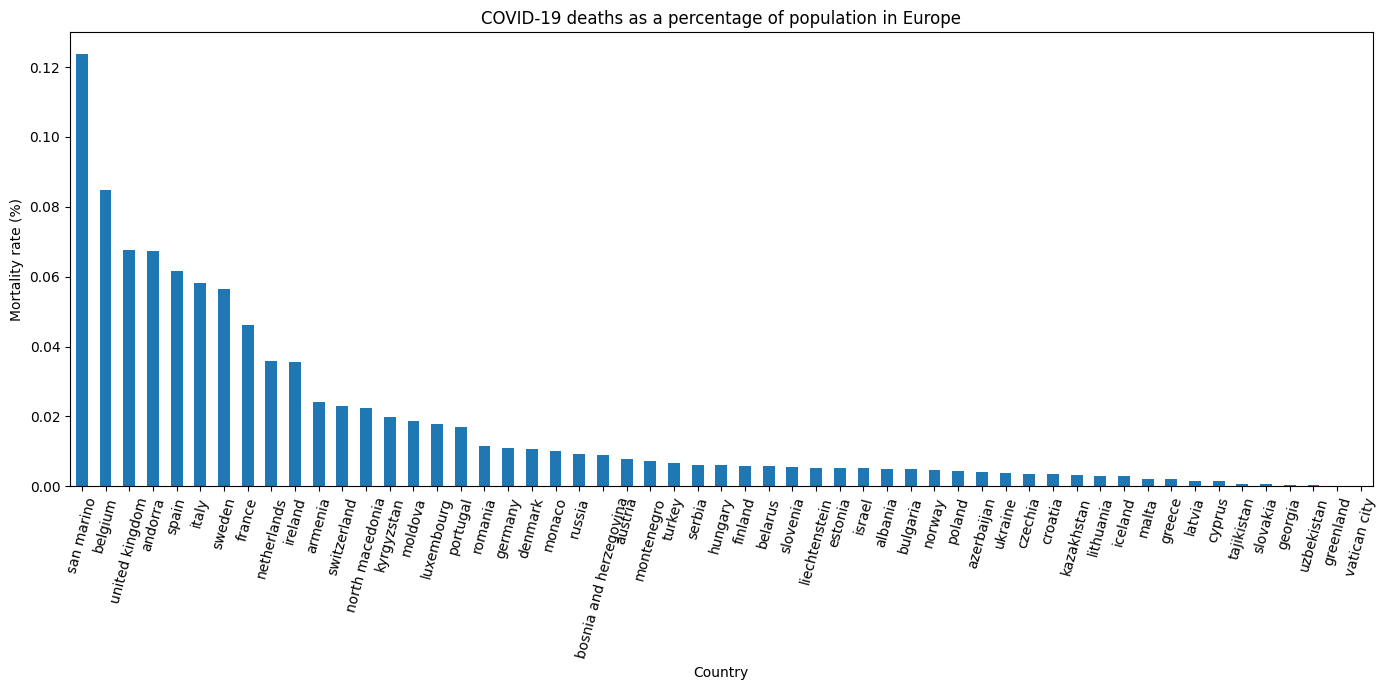

In [30]:
ax = df_europe_summary.plot(
    kind="bar",
    x="country",
    y="mortality_rate",
    figsize=(14, 7),
    legend=False
)

ax.set_title(
    "COVID-19 deaths as a percentage of population in Europe"
)
ax.set_xlabel("Country")
ax.set_ylabel("Mortality rate (%)")

plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

**Visualizing the mortality rates**

   ```python
   ax = df_europe_summary.plot(
       kind="bar",
       x="country",
       y="mortality_rate",
       figsize=(14, 7),
       legend=False
   )
   ```

   A bar chart is created with one bar for each country. The country names are shown on the horizontal axis, and the mortality rates are shown on the vertical axis.

   ```python
   ax.set_title(
       "COVID-19 deaths as a percentage of population in Europe"
   )
   ax.set_xlabel("Country")
   ax.set_ylabel("Mortality rate (%)")

   plt.xticks(rotation=75)
   plt.tight_layout()
   plt.show()
   ```

   These commands add a title and axis labels, rotate the country names so they are easier to read, adjust the layout, and display the chart.


### Insights from the plot

The bar chart shows how the calculated COVID-19 mortality rate relative to population varies across European countries.

Several observations can be made:

- **San Marino has the highest calculated mortality rate** in this dataset. However, San Marino has a very small population, so a relatively small number of deaths can result in a comparatively large percentage.
- **Belgium has the highest rate among the larger European countries** in this summary.
- The United Kingdom, Andorra, Spain, Italy, and Sweden also have relatively high mortality rates compared with many other European countries.
- Countries with larger populations do not necessarily have the highest mortality rates. This illustrates why rates can be more informative than raw death counts when comparing countries of different sizes.
- The plot includes only countries that could be matched between the COVID dataset and the Worldometer population data. Countries missing from either dataset are excluded by the inner merge.

These results should be interpreted carefully. The death counts represent the largest cumulative values available in the COVID time series, while the population values come from an undated Worldometer snapshot. In addition, differences in testing, reporting practices, healthcare systems, population age structures, and definitions of COVID-related deaths may affect the comparison.

Therefore, the plot describes differences in the reported mortality rate in this historical dataset. It does not establish that one country caused a higher mortality rate than another, nor does it provide a current estimate.

## **Bivariate Analysis with Data Visualization**

### Comparing Death and Recovery Rates among Confirmed Cases in Europe

**What is the relationship between the reported death rate and recovery rate among confirmed cases across European countries?**

Bivariate analysis examines the relationship between two variables. Here, each point in the scatter plot represents one European country. The horizontal axis shows the percentage of confirmed cases associated with deaths, while the vertical axis shows the percentage associated with reported recoveries.

In this section, both rates use confirmed cases as their denominator:

$$
\text{Death Rate among Confirmed Cases (\%)} =
\left(
\frac{\text{Deaths}}{\text{Confirmed Cases}}
\right)
\times 100
$$

$$
\text{Recovery Rate (\%)} =
\left(
\frac{\text{Recovered Cases}}{\text{Confirmed Cases}}
\right)
\times 100
$$

The plot allows us to examine whether countries with a higher reported recovery rate also tend to have a higher or lower reported death rate. It may also help us identify countries that appear unusual compared with the general pattern.

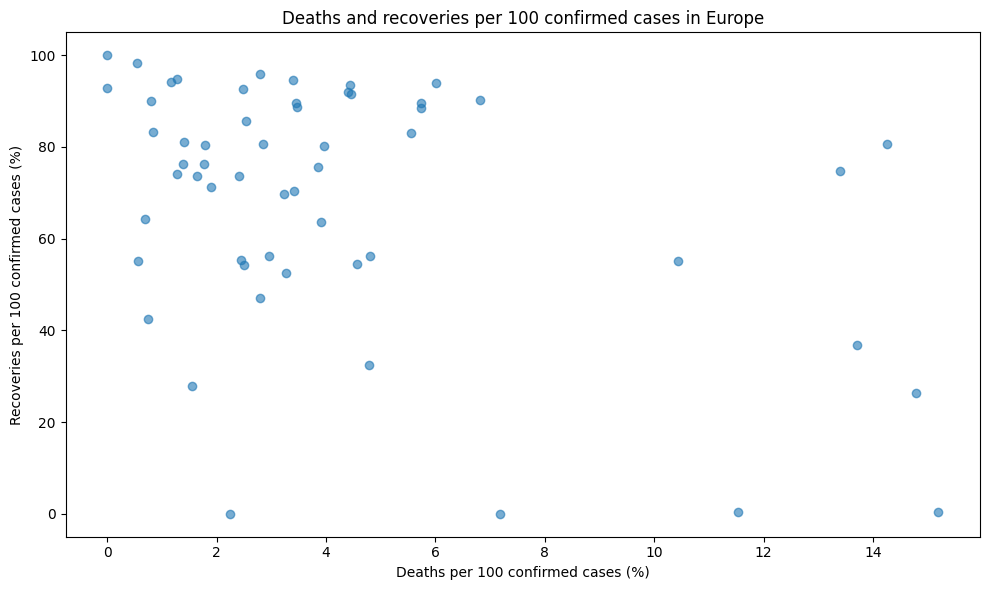

In [31]:
df_europa_daily = (
    df_europe
    .groupby(["country", "date"])[
        ["confirmed", "deaths", "recovered"]
    ]
    .sum()
    .reset_index()
)

# Convert dates so that the latest date can be selected correctly
df_europa_daily["date"] = pd.to_datetime(
    df_europa_daily["date"]
)

# Select the latest observation for each country
df_europa_latest = (
    df_europa_daily
    .sort_values("date")
    .groupby("country")
    .tail(1)
)

# Avoid division by zero
df_europa_filtered = df_europa_latest[
    df_europa_latest["confirmed"] > 0
].copy()

# These are rates relative to confirmed cases
df_europa_filtered["deaths_per_100_confirmed"] = (
    df_europa_filtered["deaths"]
    / df_europa_filtered["confirmed"]
    * 100
)

df_europa_filtered["recovered_per_100_confirmed"] = (
    df_europa_filtered["recovered"]
    / df_europa_filtered["confirmed"]
    * 100
)

plt.figure(figsize=(10, 6))

plt.scatter(
    df_europa_filtered["deaths_per_100_confirmed"],
    df_europa_filtered["recovered_per_100_confirmed"],
    alpha=0.6
)

plt.title(
    "Deaths and recoveries per 100 confirmed cases in Europe"
)
plt.xlabel("Deaths per 100 confirmed cases (%)")
plt.ylabel("Recoveries per 100 confirmed cases (%)")
plt.tight_layout()
plt.show()

### Interpreting the scatterplot

Each point represents one country. Its horizontal position is determined by the mortality rate and its vertical position by the recovery rate. A downward pattern might suggest an inverse association, while a cloud of points with no clear direction suggests a weak linear association. These are descriptions of association, not evidence of causation.

### 
### Correlation analysis - The `corr()` Command

The [`corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html) function in pandas calculates the **correlation** between numerical columns in a DataFrame. Correlation measures the statistical relationship between two variables, indicating whether and how strongly pairs of variables are related.

#### Key Points:
- **Range of Correlation**:
  - Values range from **-1** to **1**.
  - **1** indicates a perfect positive correlation (as one variable increases, the other increases).
  - **-1** indicates a perfect negative correlation (as one variable increases, the other decreases).
  - **0** indicates no correlation (no linear relationship between the variables).
  
- **Usage**:
  - `df.corr()`: Returns a correlation matrix showing the correlation coefficients between all pairs of numerical columns in the DataFrame.
  
- **Purpose**:
  - It helps identify relationships between variables, which can be useful for feature selection in data analysis and machine learning.

In [32]:
df_corr = covid_complete[
    ['confirmed', 'deaths', 'recovered', 'active']
]
correlation_matrix = df_corr.corr()
correlation_matrix

,confirmed,deaths,recovered,active
confirmed,1.00,0.91,0.90,0.95
deaths,0.91,1.00,0.76,0.89
recovered,0.90,0.76,1.00,0.71
active,0.95,0.89,0.71,1.00


### Visualizing the correlation matrix

A heatmap represents correlation values with colors. The diagonal should contain `1.00`, because each variable is perfectly correlated with itself. The upper and lower triangles should mirror one another because the correlation between variable A and variable B is the same as the correlation between variable B and variable A.

The numbers written on top of the colors make the approximate values easier to read.

To learn more:

- [Matplotlib `imshow()` documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html) explains how the matrix is displayed as an image.
- [Matplotlib `colorbar()` documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.colorbar.html) explains the color scale shown beside the heatmap.
- [Matplotlib colormap guide](https://matplotlib.org/stable/users/explain/colors/colormaps.html) explains how color maps such as `coolwarm` represent numerical values.

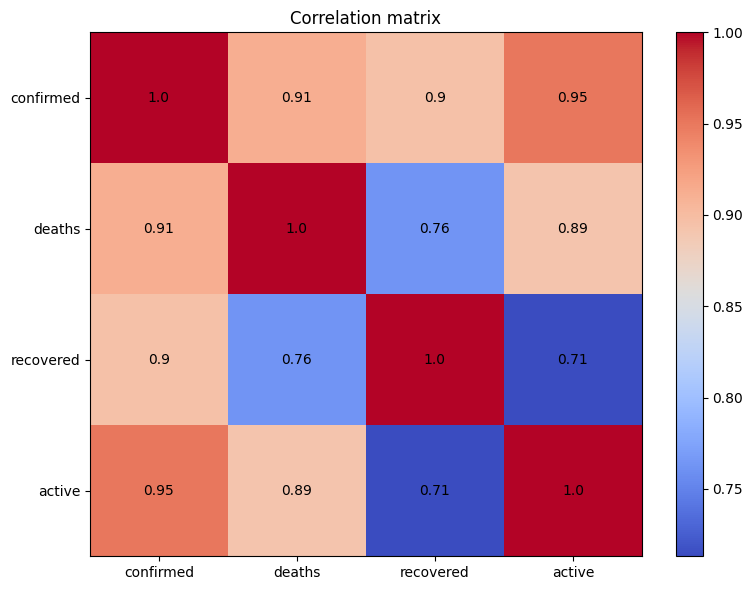

In [33]:
plt.figure(figsize=(8, 6))
plt.imshow(
    correlation_matrix,
    cmap='coolwarm',
    interpolation='none',
    aspect='auto'
)
plt.colorbar()
plt.xticks(
    np.arange(len(correlation_matrix.columns)),
    correlation_matrix.columns
)
plt.yticks(
    np.arange(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j, i, round(correlation_matrix.iloc[i, j], 2),
            ha='center', va='center', color='black'
        )

plt.title('Correlation matrix')
plt.tight_layout()
plt.show()

### Reading the heatmap

The color scale helps us locate strong positive and negative associations quickly, while the printed values provide the precise numbers. The heatmap does not solve temporal misalignment or causality problems. A strong color is a reason to investigate further, not a final conclusion.

### How multivariate analysis fits in

Multivariate analysis considers three or more variables at the same time. The correlation matrix is a gentle first connection because it summarizes many pairwise comparisons in one table. Each individual cell, however, still compares only two variables.

The lecture material also shows advanced multivariate visualizations such as contour plots and three-dimensional scatterplots. Due to limited time, unfortunately we won't see it during the lab, but I have below a lot more analysis like the two above that we just saw for your projects/exam.

## Recap

1. Inspect the data before changing it.
2. Standardize column names and key values.
3. Decide carefully whether to drop or impute missing values based on the domain knowledge you have from the dataset.
4. Merge only after checking that the key values are compatible and if and when the merging makes sense.
5. Use univariate summaries and plots to understand one variable.
6. Use bivariate plots and correlations to compare two variables.
7. Treat multivariate analysis as the next step when a question involves several variables.



# Supplementary Material

## Optional material and dataset reminder

The following sections are optional extensions. They are provided for students who want to explore the analyses from the solution notebook in more depth; they are not required for the scheduled lab.

The datasets have different structures:

- covid_complete_clean is a daily COVID time series. Its cumulative columns describe the situation on each date.
- worldometer is an undated country-level snapshot.
- country_wise_latest.csv is another country-level snapshot with “new” values for the snapshot represented by that file.

The original solution notebook included analyses based on grouped_df_merge, which was created after merging the two datasets only on country. That merge is useful for discussing why a technically successful merge can still be a poor analytical choice, but it should not be used for totals, correlations, or visual conclusions. The code below deliberately uses corrected summaries derived from the COVID time series and labels snapshot comparisons explicitly.

## Optional: checking the definition of active cases

The COVID dataset contains confirmed, deaths, recovered, and active. A useful data-quality check is to test whether the reported active cases equal:

confirmed - deaths - recovered

The all method returns one Boolean value for the complete comparison. It is True only when every row satisfies the comparison. The values arrays are compared element by element before all summarizes the result.

This is a consistency check, not a proof that the data are correct: the four columns could still contain the same systematic error.

For the official pandas documentation, see:
https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.all.html

In [34]:
calculated_active = (
    covid_complete["confirmed"]
    - covid_complete["deaths"]
    - covid_complete["recovered"]
)

active_matches = (
    calculated_active.values
    == covid_complete["active"].values
).all()

active_matches

np.True_

## Optional: create a time-aware country-level COVID summary

A country can appear several times on the same date because the original data may contain state or province rows. We first add those rows together for each country and date. We then take the maximum cumulative value observed for each country.

This is different from summing cumulative values over dates. A cumulative value already includes earlier dates, so summing it across the whole time series would count the same cases repeatedly. Taking the maximum gives a simple estimate of the latest cumulative value in this dataset.

In [35]:
covid_country_daily = (
    covid_complete
    .groupby(["country", "date"])[
        ["confirmed", "deaths", "recovered", "active"]
    ]
    .sum()
)

covid_country_summary = (
    covid_country_daily
    .groupby("country")[
        ["confirmed", "deaths", "recovered", "active"]
    ]
    .max()
    .reset_index()
)

covid_country_summary.head()

,country,confirmed,deaths,recovered,active
0,afghanistan,36263,1269,25198,20311
1,albania,4880,144,2745,1991
2,algeria,27973,1163,18837,8114
3,andorra,907,52,803,504
4,angola,950,41,242,667


## Optional: a country-level merge

If we want to compare the COVID time series with Worldometer information, we should first reduce the time series to one row per country. This prevents the same Worldometer row from being repeated once for every COVID date.

The merge below is structurally cleaner because both inputs have one row per country. It is still not a perfectly time-aligned comparison: the COVID summary represents the latest date available in that file, while Worldometer is an undated snapshot. We therefore describe this as an exploratory comparison, not as a precise measurement at one shared date.

The validate="one_to_one" argument asks pandas to verify that each country occurs at most once on each side.

In [36]:
worldometer_americas = worldometer[
    worldometer["continent"].isin(["North America", "South America"])
].copy()

covid_americas_summary = covid_country_summary[
    covid_country_summary["country"].isin(worldometer_americas["country"])
].copy()

americas_snapshot_merge = pd.merge(
    covid_americas_summary,
    worldometer_americas,
    on="country",
    how="inner",
    validate="one_to_one",
    suffixes=("_covid", "_worldometer"),
)

print("Merged shape:", americas_snapshot_merge.shape)
americas_snapshot_merge.head()

Merged shape: (36, 20)


,country,confirmed,deaths,recovered,active,continent,population,total_cases,new_cases,total_deaths,new_deaths,total_recovered,new_recovered,active_cases,serious_critical,total_cases_per_1m,deaths_per_1m,total_tests,tests_per_1m,who_region
0,antigua and barbuda,86,3,65,44,North America,98010.00,92,NaN,3.00,NaN,76.00,NaN,13.00,1.00,939.00,31.00,1500.00,15305.00,Americas
1,argentina,167416,3059,72575,91782,South America,45236884.00,228195,NaN,4251.00,NaN,99852.00,NaN,124092.00,1150.00,5044.00,94.00,794544.00,17564.00,Americas
2,bahamas,382,11,91,280,North America,393616.00,761,NaN,14.00,NaN,91.00,NaN,656.00,1.00,1933.00,36.00,4814.00,12230.00,Americas
3,barbados,110,7,94,56,North America,287411.00,133,NaN,7.00,NaN,100.00,NaN,26.00,NaN,463.00,24.00,12233.00,42563.00,Americas
4,belize,48,2,26,20,North America,398312.00,86,NaN,2.00,NaN,31.00,NaN,53.00,2.00,216.00,5.00,3679.00,9236.00,Americas


## Optional: a multivariate comparison of the largest countries

This plot compares four country-level quantities at the latest observed point in the COVID time series. It uses covid_country_summary, not the country-only merged table.

A grouped bar chart is used instead of a stacked bar chart. Confirmed cases include people who are recovered or deceased, so stacking confirmed cases, deaths, and recovered cases would suggest that these are separate additive parts of one total and would visually double-count information.

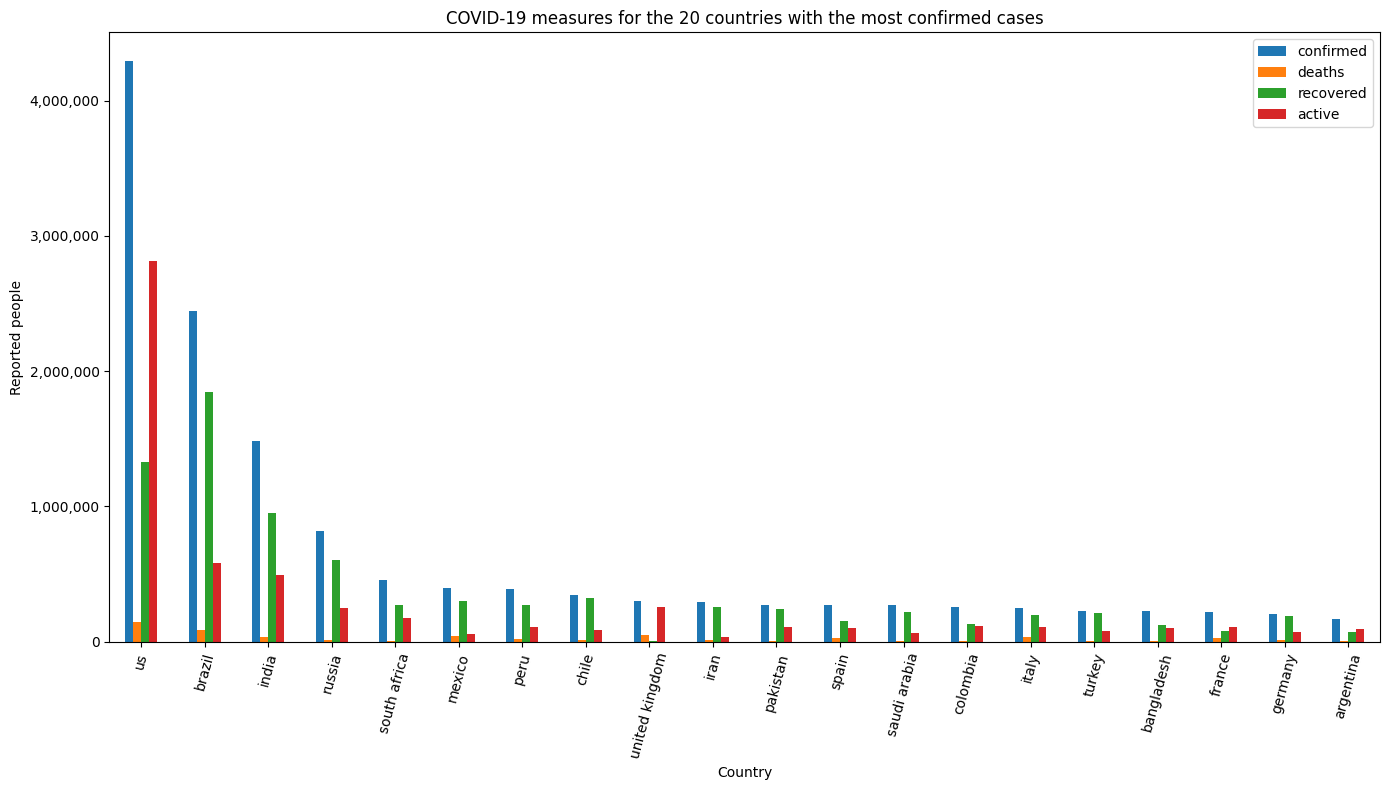

In [37]:
import matplotlib.ticker as mtick

top_20_countries = (
    covid_country_summary
    .sort_values("confirmed", ascending=False)
    .head(20)
    .set_index("country")
)

ax = top_20_countries[
    ["confirmed", "deaths", "recovered", "active"]
].plot(
    kind="bar",
    figsize=(14, 8)
)

ax.set_title("COVID-19 measures for the 20 countries with the most confirmed cases")
ax.set_xlabel("Country")
ax.set_ylabel("Reported people")
ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## Optional: Multivariate Analysis: Comparing New Deaths, New Cases and New Recovered

In this analysis, we are comparing multiple variables: **New Deaths**, **New Cases** and **New Recovered** across various European countries. Visualizing these three variables together allows us to understand the relationship between different aspects of COVID-19's impact in each country. 

Since we are analyzing multiple variables simultaneously, this is considered a **multivariate analysis**. By comparing New Deaths, New Cases, and New Recovered, we can observe trends in how different countries are managing new outbreaks and recoveries.

This type of analysis helps in understanding which countries are experiencing higher rates of new cases, deaths, or recoveries and how these variables compare to one another across the region.

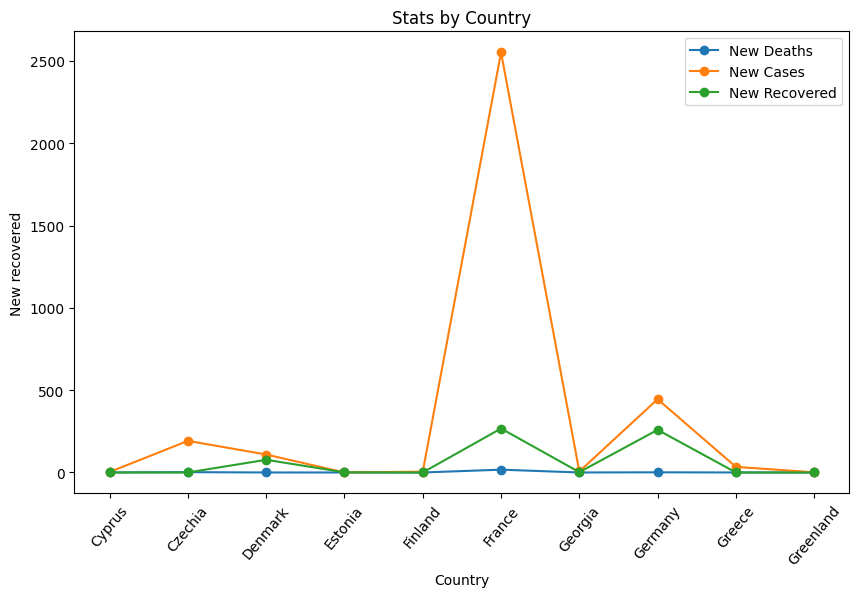

In [38]:
# Load the dataset
df = pd.read_csv('country_wise_latest.csv')

# Filter the data for European countries and select rows 10 to 21
df_eu = df[df['WHO Region'] == 'Europe'].iloc[10:21].head(10)

# Set up the figure size for the plot
plt.figure(figsize=(10, 6))

# Plot new deaths for the selected countries with markers
plt.plot(df_eu['Country/Region'], df_eu['New deaths'], marker='o', label='New Deaths')

# Plot new cases for the selected countries with markers
plt.plot(df_eu['Country/Region'], df_eu['New cases'], marker='o', label='New Cases')

# Plot new recoveries for the selected countries with markers
plt.plot(df_eu['Country/Region'], df_eu['New recovered'], marker='o', label='New Recovered')

# Set the title of the plot
plt.title('Stats by Country')

# Set the label for the x-axis
plt.xlabel('Country')

# Set the label for the y-axis (Note: Change it to reflect the variables being plotted)
plt.ylabel('New recovered')

# Rotate the x-axis labels by 50 degrees for better readability
plt.xticks(rotation=50)

# Add a legend to distinguish the plotted lines
plt.legend()

# Save the plot as a PNG image
plt.savefig('new_deaths_new_cases_recovered_stats_by_country.png')

# Display the plot
plt.show()

### Interpretation of the Line Plot for Stats by Country

The line plot above shows the comparison between **New Deaths**, **New Cases**, and **New Recovered** cases across selected European countries. 

- **France** stands out with the highest number of new cases (~2500), which is significantly higher than other countries in this dataset.
- **New Deaths** across all countries are relatively low compared to the number of new cases, with small spikes in Germany and France.
- The number of **New Recovered** cases generally follows a steady trend, with minor peaks in Finland and France.

This plot helps to understand how various countries are handling new cases, recoveries, and deaths, where some countries show a proportionally larger rise in new cases but relatively lower recoveries and deaths, reflecting the ongoing nature of the pandemic in these regions.


### **Bivariate Analysis of COVID-19 Deaths and Recoveries Ratios**

This script performs a **bivariate analysis** by visualizing two related variables: the ratio of COVID-19 deaths and recoveries per 100 cases for the top 15 countries with the highest ratios. The dataset is sourced from a CSV file, and the goal is to use a horizontal bar chart to compare these two important metrics across different countries.

By examining the ratio of deaths and recoveries side by side, we can gain insights into how different countries have managed the pandemic, highlighting countries with high mortality rates versus those with strong recovery rates. This type of analysis helps in understanding the relationship between two variables within the same context (e.g., the pandemic's impact across countries).

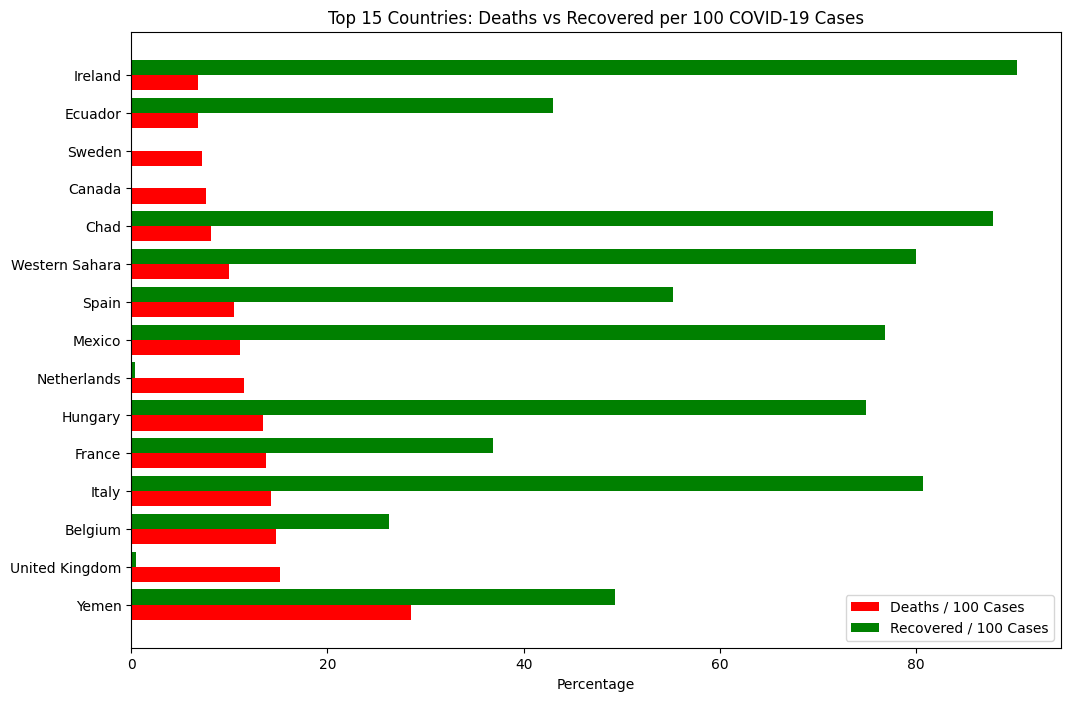

In [39]:
df = pd.read_csv('country_wise_latest.csv')

# Select and sort the top 15 countries with the highest ratio for Deaths/100 Cases and Recovered/100 Cases
df = df.sort_values(by=['Deaths / 100 Cases', 'Recovered / 100 Cases'], ascending=False).head(15)

y_pos = np.arange(len(df['Country/Region']))
# Set the figure size
plt.figure(figsize=(12, 8))

# Plot the first horizontal bar for Deaths / 100 Cases
plt.barh(y_pos, df['Deaths / 100 Cases'], height=0.4, label='Deaths / 100 Cases', color='red')

# Plot the second horizontal bar for Recovered / 100 Cases, with an offset on the y-axis
plt.barh(y_pos + 0.4, df['Recovered / 100 Cases'], height=0.4, label='Recovered / 100 Cases', color='green')

# Add labels and title
plt.yticks(y_pos + 0.2, df['Country/Region'])  # Align the country names between the two bars
plt.xlabel('Percentage')
plt.title('Top 15 Countries: Deaths vs Recovered per 100 COVID-19 Cases')

# Add a legend to differentiate the two series
plt.legend()

plt.savefig('top_15_deaths_vs_recovered.png')

# Show the plot
plt.show()

### Main Insights from Top 15 Countries: Deaths vs Recovered per 100 COVID-19 Cases

1. **Yemen** has the highest death ratio per 100 cases, indicating a significantly higher fatality rate compared to other countries.
2. **Western Sahara** and **Chad** have relatively high recovery rates, with very few deaths per 100 cases, reflecting effective recovery management.
3. **European countries** like **Italy** and **Belgium** show a moderate balance between recovery and death rates, suggesting a more even distribution of outcomes.

### **Univariate Analysis of COVID-19 Growth Rate in the USA**

In this section, we aim to calculate and analyze the COVID-19 growth rate for the United States. Specifically, we will focus on determining how the number of confirmed cases has increased over time. The growth rate will be computed based on the number of new cases reported each month, providing insights into how rapidly the pandemic has been spreading.

### Objectives:

1. **Load the Dataset**:
   - We start by loading the dataset containing COVID-19 statistics, which includes data on confirmed cases, deaths, recoveries, and other relevant metrics by date and country.

2. **Filter Data for the USA**:
   - Extract data specifically for the United States to focus our analysis on this region.

3. **Calculate Monthly Growth Rate**:
   - Using the filtered data, calculate the monthly growth rate of confirmed cases. **Note:** Ensure the 'Date' column is converted to the correct format for accurate aggregation.
   - The percentage change in confirmed cases from one month to the next will give us the growth rate.
   - Clean the data as needed (e.g., handling missing or incorrect values) to ensure accuracy in analysis.

4. **Visualize the Growth Rate**:
   - Create a line plot to visualize the monthly growth rate over time. This will help identify patterns in how the rate of new COVID-19 cases has evolved in the USA.

This analysis is a **univariate analysis** as it focuses on a single variable—the growth rate of confirmed cases over time. By performing this analysis, we will gain insights into the dynamics of COVID-19 spread in the USA, allowing us to track increases or decreases in the rate of new infections.

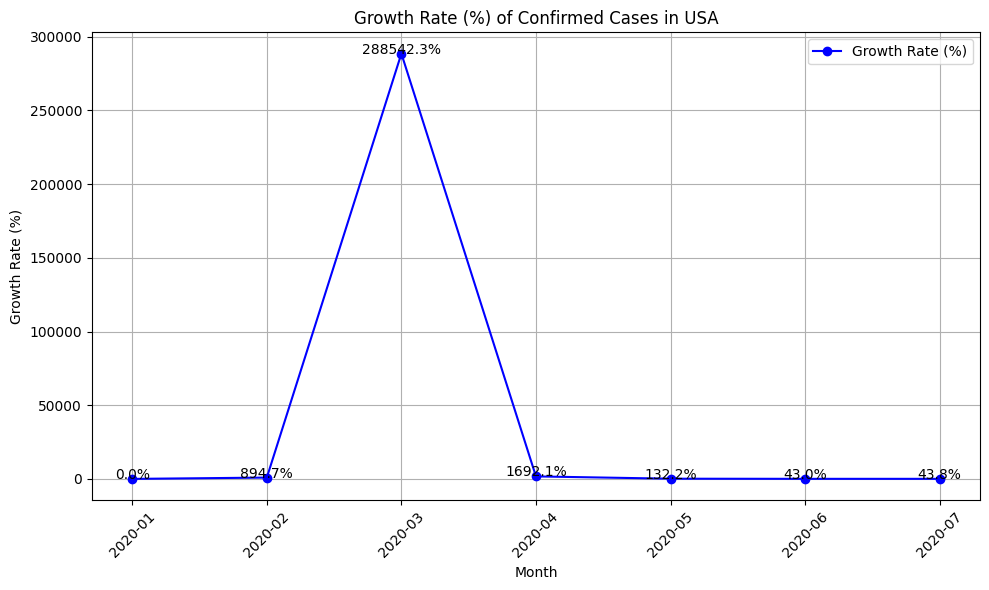

In [40]:
# Filter the dataset to include only records for the United States
df_USA = covid_complete[covid_complete['country'] == 'us']

# Remove columns with missing values to clean the dataset
df_USA.dropna(axis=1, inplace=True)

# Convert the 'date' column to datetime type for proper aggregation by month
df_USA['date'] = pd.to_datetime(df_USA['date'])

# Group the data by month and aggregate sum for confirmed, deaths, recovered, active cases, and first value for lat/long
df_USA_grouped = df_USA.groupby(df_USA['date'].dt.to_period('M')).agg({
    'confirmed': 'sum',
    'deaths': 'sum',
    'recovered': 'sum',
    'active': 'sum',
    'lat': 'first',
    'long': 'first'
}).reset_index()

# Calculate the monthly growth rate for confirmed cases
df_USA_grouped['growth_rate'] = df_USA_grouped['confirmed'].pct_change() * 100

# Fill any NaN values in the dataset with 0
df_USA_grouped.fillna(0, inplace=True)

# Create a plot with a specified figure size
plt.figure(figsize=(10, 6))

# Plot the growth rate over time with markers on the data points
plt.plot(df_USA_grouped['date'].dt.strftime('%Y-%m'), df_USA_grouped['growth_rate'], marker='o', color='b', label='Growth Rate (%)')

# Annotate each data point with the growth rate percentage on the plot
for i in range(len(df_USA_grouped)):
    growth_rate = df_USA_grouped['growth_rate'].iloc[i]
    if not pd.isna(growth_rate):  # Skip NaN values
        plt.text(df_USA_grouped['date'].dt.strftime('%Y-%m').iloc[i], growth_rate + 2, f'{growth_rate:.1f}%', ha='center', color='black')

# Label the x-axis as 'Month'
plt.xlabel('Month')

# Label the y-axis as 'Growth Rate (%)'
plt.ylabel('Growth Rate (%)')

# Set the title of the plot
plt.title('Growth Rate (%) of Confirmed Cases in USA')

# Rotate the x-axis labels for better readability
plt.xticks(rotation=45)

# Add gridlines to the plot
plt.grid(True)

# Add a legend to explain the data being plotted
plt.legend()

# Optimize the layout so that labels and titles fit well within the plot
plt.tight_layout()

# Save the figure as a PNG file
plt.savefig('growth_rate_usa.png')

# Show the plot
plt.show()

### Grouping and Aggregating Data by Month

The `agg()` function is used to perform multiple aggregations on different columns after grouping the data by month. Here's what happens in this step:

- We group the data by the **month** (using the `.dt.to_period('M')` to extract the month from the date).
- For each column:
  - `confirmed`, `deaths`, `recovered`, and `active` cases are **summed** for each month to get the total monthly values.
  - `lat` and `long` represent geographical coordinates, so we take the **first** value for each month, as these values remain constant for the USA.

This step results in a new DataFrame (`df_USA_grouped`) where each row corresponds to a month, and the columns represent the aggregated monthly statistics.


### **Interpretation of COVID-19 Growth Rate in the USA**

This chart illustrates the growth rate (%) of confirmed COVID-19 cases in the USA from January 2020 to July 2020. The x-axis shows the months, and the y-axis represents the growth rate percentage. There is an extreme spike in growth in March 2020, reaching a rate of 288,542.3%, reflecting the early explosion of cases. After that, the growth rate significantly decreases, with rates around 169.1% in April, 132.2% in May, and stabilizing at around 43% in June and July. This indicates a rapid initial spread followed by a slower growth in confirmed cases.

## **Bivariate Analysis with Seaborn: Growth of Confirmed Cases Around the World**

In this section we provide an example of the usage of the Seaborn library, to see also the difference with MatplotLib Library


The sns.set() (https://seaborn.pydata.org/generated/seaborn.set.html) function in Seaborn is used to set the default aesthetics and theme for visualizations. It adjusts the appearance of plots, making them look more visually appealing and ready for presentation with minimal effort. It modifies things like colors, gridlines, font sizes, and styles, making the plots more modern and cleaner than the default Matplotlib settings.

In [41]:
sns.set()


The code defines a list of six countries of interest and then filters the dataset covid_complete to only include rows corresponding to those countries. The isin() (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isin.html) function is used to match the countries in the dataset's "country" column with the list. The resulting data contains information specific to these selected countries, though there is no date filter applied yet for data after March 1st.

In [42]:
#our analysis will focus on some countries we put in a list
countries = ["morocco","algeria","egypt","nigeria","iraq","ghana"]

#from the dataset, we will extract the data concerning the countries in the list. we are interested in the period after March 1st
data=covid_complete[(covid_complete["country"].isin(countries))]

This code creates a line chart showing the daily accumulation of confirmed cases for each country in the list, with the following steps:

1. **Setting the figure size**:
   - `fig=plt.figure(figsize=(16,8))` creates a figure with a width of 16 inches and height of 8 inches to ensure enough space for the plot and its elements.
   
2. **Plotting the line chart**:
   - `sns.lineplot(x=data.date, y=data['confirmed'], hue="country", data=data)` creates a line chart where the x-axis represents the dates and the y-axis shows the confirmed cases. The `hue="country"` argument differentiates the lines by country, displaying a separate line for each country in the list.
   
3. **Reducing label density on the x-axis**:
   - The `for` loop goes through each x-axis label (representing dates) and only makes every 20th label visible. This prevents overcrowding of labels on the x-axis and improves readability of the plot.

This produces a clean and informative line plot that compares the confirmed COVID-19 cases for selected countries over time.

### Why this is Bivariate Analysis:
This is considered **bivariate analysis** because it examines the relationship between two variables: **time (date)** on the x-axis and **confirmed cases** on the y-axis. By analyzing how the confirmed cases change over time, we are exploring the interaction between these two variables.

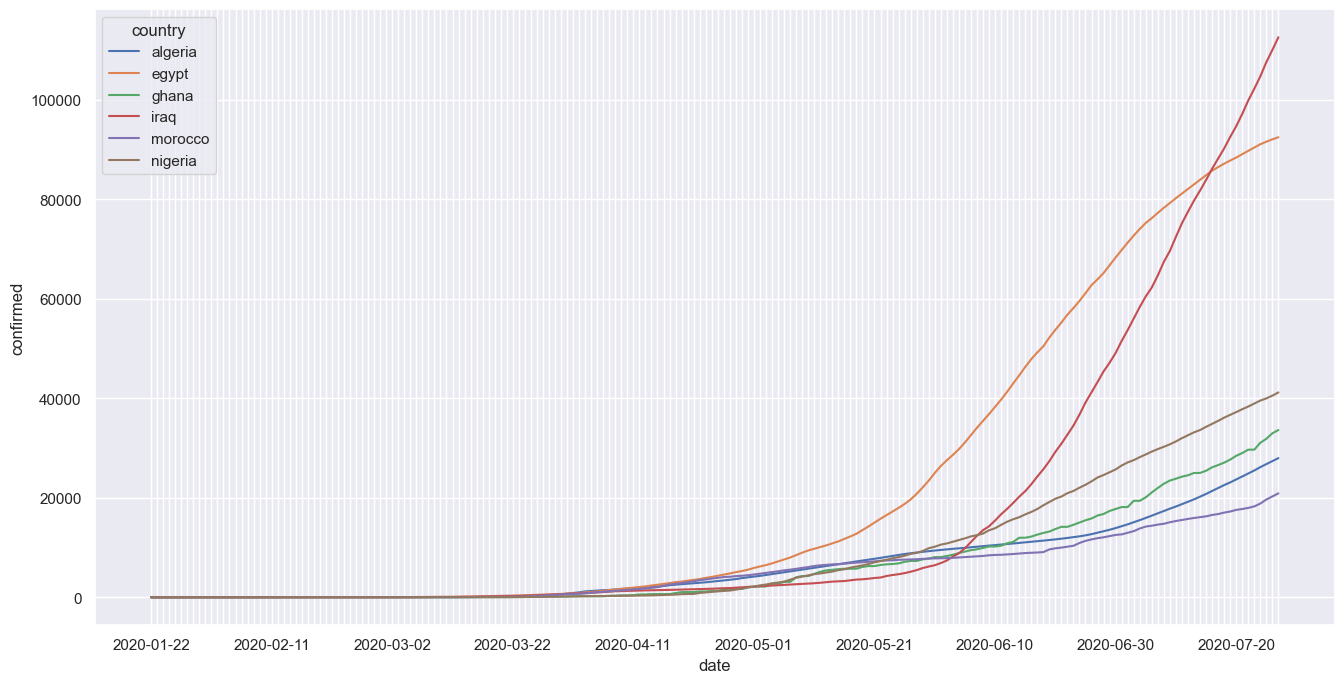

In [43]:
# Set the figure size for the plot (16 inches wide and 8 inches tall)
fig = plt.figure(figsize=(16, 8))

# Line chart showing the day-to-day accumulation of confirmed cases for each country in the list
plot_ = sns.lineplot(x=data.date, y=data['confirmed'], hue="country", data=data)

# Reduce the density of x-axis labels to avoid overcrowding
for ind, label in enumerate(plot_.get_xticklabels()):
    if ind % 20 == 0:  # Show every 20th label
        label.set_visible(True)
    else:
        label.set_visible(False)

# Save the plot as a PNG image
plt.savefig('confirmed_cases_by_country.png')

# Show the plot
plt.show()

In [44]:
sns.set()


The code defines a list of six countries of interest and then filters the dataset covid_complete to only include rows corresponding to those countries. The isin() (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isin.html) function is used to match the countries in the dataset's "country" column with the list. The resulting data contains information specific to these selected countries, though there is no date filter applied yet for data after March 1st.

In [45]:
#our analysis will focus on some countries we put in a list
countries = ["morocco","algeria","egypt","nigeria","iraq","ghana"]

#from the dataset, we will extract the data concerning the countries in the list. we are interested in the period after March 1st
data=covid_complete[(covid_complete["country"].isin(countries))]

This code creates a line chart showing the daily accumulation of confirmed cases for each country in the list, with the following steps:

1. **Setting the figure size**:
   - `fig=plt.figure(figsize=(16,8))` creates a figure with a width of 16 inches and height of 8 inches to ensure enough space for the plot and its elements.
   
2. **Plotting the line chart**:
   - `sns.lineplot(x=data.date, y=data['confirmed'], hue="country", data=data)` creates a line chart where the x-axis represents the dates and the y-axis shows the confirmed cases. The `hue="country"` argument differentiates the lines by country, displaying a separate line for each country in the list.
   
3. **Reducing label density on the x-axis**:
   - The `for` loop goes through each x-axis label (representing dates) and only makes every 20th label visible. This prevents overcrowding of labels on the x-axis and improves readability of the plot.

This produces a clean and informative line plot that compares the confirmed COVID-19 cases for selected countries over time.

### Why this is Bivariate Analysis:
This is considered **bivariate analysis** because it examines the relationship between two variables: **time (date)** on the x-axis and **confirmed cases** on the y-axis. By analyzing how the confirmed cases change over time, we are exploring the interaction between these two variables.

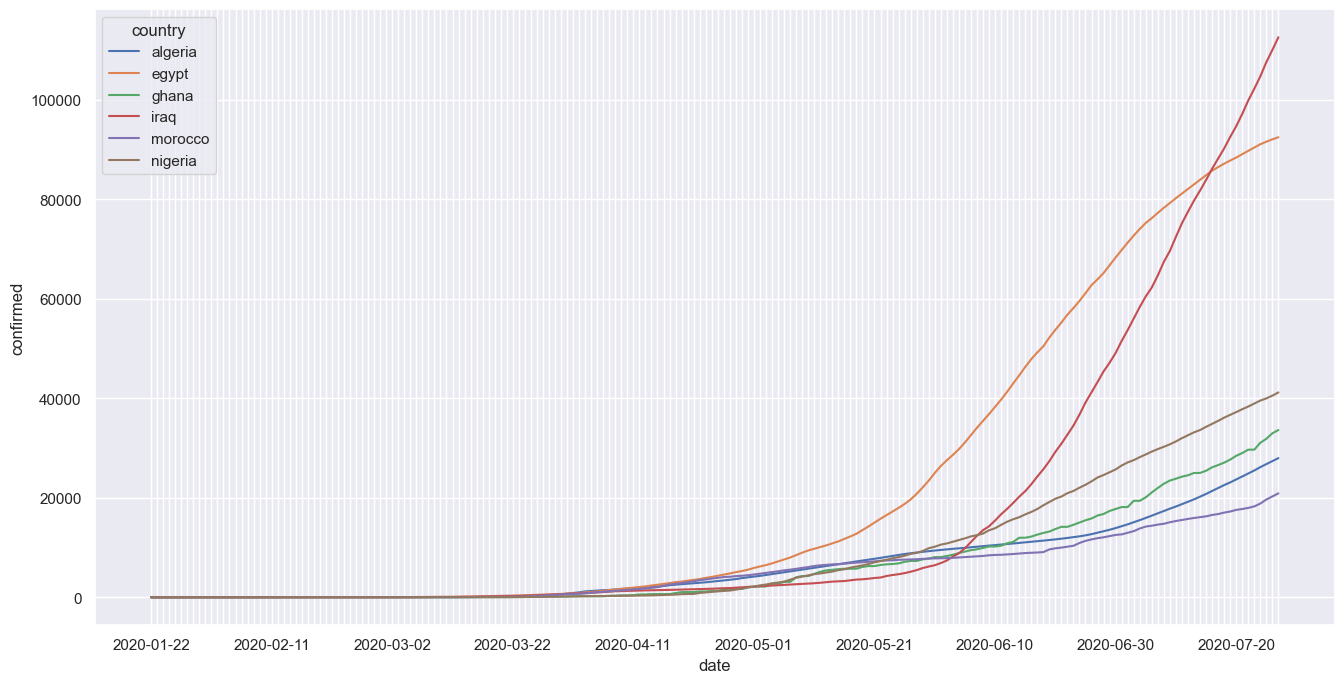

In [46]:
# Set the figure size for the plot (16 inches wide and 8 inches tall)
fig = plt.figure(figsize=(16, 8))

# Line chart showing the day-to-day accumulation of confirmed cases for each country in the list
plot_ = sns.lineplot(x=data.date, y=data['confirmed'], hue="country", data=data)

# Reduce the density of x-axis labels to avoid overcrowding
for ind, label in enumerate(plot_.get_xticklabels()):
    if ind % 20 == 0:  # Show every 20th label
        label.set_visible(True)
    else:
        label.set_visible(False)

# Save the plot as a PNG image
plt.savefig('confirmed_cases_by_country.png')

# Show the plot
plt.show()